# Calling your own functions with TypeSafe

<a href="https://colab.research.google.com/github/sixhobbits/colab-demo/blob/main/cookbooks/function_calling/function_calling.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in%20Colab-F9AB00?style=for-the-badge&logo=googlecolab&logoColor=white" alt="Open in Colab" height="28"></a> <a href="https://github.com/sixhobbits/colab-demo/blob/main/cookbooks/function_calling/function_calling.ipynb" target="_blank"><img src="https://img.shields.io/badge/View%20on%20GitHub-24292F?style=for-the-badge&logo=github&logoColor=white" alt="View on GitHub" height="28"></a>

> **No API key needed.** The code downloads this cookbook's saved answers, so
> *Run all* replays every TypeSafe call from them. It needs no TypeSafe account
> and costs nothing. To call the API yourself, set `TYPESAFE_API_KEY` and
> `DOWNLOAD_CACHE = False`.

From [the docs page](https://console.typesafe.ai/docs/cookbooks/function_calling).

When you order a "large iced oat latte, no sweetener," the barista does not write your
sentence down. They mark four options on a cup. This cookbook does the same thing for
a trading API: a sentence goes in, and out comes a function name and its arguments as
evaluated enums, each with a confidence.

```text
"plot rolling correlation between nvda and spy for the past month"
    rolling_correlation(symbol='NVDA', benchmark='SPY', window='1mo')   confidence 0.93

"compare nvda amd and msft over the past three months"
    compare_returns(symbols=['NVDA', 'AMD', 'MSFT'], window='3mo')      confidence 0.93

"show me apple daily with volume"
    plot_price(symbol='AAPL', resolution='1d', include_volume=True)     confidence 0.69

"what tickers do you have"
    list_symbols()                                                     confidence 1.00
```

Those calls go to ten ordinary functions in a trading assistant. Their arguments take
values from fixed lists, so they are `Literal`s already:

```python
def plot_price(
    symbol: Literal["SPY", "NVDA", "AMD", "AAPL", "MSFT", "TSLA"],
    style: Literal["line", "candles"] = "line",
    resolution: Literal["1m", "5m", "15m", "1h", "1d"] = "15m",
    window: Literal["1d", "1w", "1mo", "3mo"] = "1w",
    include_volume: bool = False,
    moving_average: Literal["9", "20", "50"] | None = None,
    log_scale: bool = False,
): ...
```

An argument whose values come from a fixed list is a closed set. When it takes one value
out of that list, it gets a `Choice` question over exactly those values, so whatever
reaches the function is a value the function accepts. You leave the functions alone. What
you add is a spec that says in plain words what each argument means. By the end you have a
`Dispatcher` you can point at your own functions.

## Setup

```bash
pip install ipython polars matplotlib numpy 'cooksafe>=0.3.0,<0.4.0'
```

Set `TYPESAFE_API_KEY`. The code below downloads two modules, with `spec.json` and the
price bars, from
[typesafe-public-examples](https://github.com/typesafe-ai/typesafe-public-examples/tree/main/cookbooks/function_calling)
unless they are already on disk. `trader.py` holds the ten functions, and `dispatch.py`
holds the code that reads a signature and a spec and makes the call.

The prices are simulated from a fixed random seed, not real market data. The tickers are
real, but every price, return and chart below is generated.

In [ ]:
%pip install -q 'typesafe-sdk>=0.7.0' 'ipython' 'polars' 'matplotlib' 'numpy' 'cooksafe>=0.3.0,<0.4.0'

In [ ]:
import json
import os
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from typesafe_sdk import SystemOneResponse, TypeSafeClient

EXAMPLES = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/function_calling"
)
for name in ["dispatch.py", "trader.py", "spec.json", "bars.parquet"]:
    if not Path(name).exists():
        urllib.request.urlretrieve(f"{EXAMPLES}/{name}", name)

from dispatch import ROUTE, Dispatcher, closed_sets  # noqa: E402  (downloaded above)
from trader import TOOLS, chart_theme, load  # noqa: E402


def show(draw) -> None:
    """Display the chart ``draw()`` makes. The docs build sets COOKSAFE_RENDER and also gets
    a dark copy."""
    for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
        with chart_theme(theme):
            figure = draw()
        display(figure, metadata={"theme": theme})
        plt.close(figure)


print(f"{len(TOOLS)} functions over {load().height:,} one-minute bars")

10 functions over 156,780 one-minute bars


In [ ]:
TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
typesafe = TypeSafeClient(
    api_key=os.environ.get("TYPESAFE_API_KEY", "cache-only"),  # keyless runs replay the cache
    base_url=os.environ.get("TYPESAFE_ENDPOINT"),
    timeout=120.0,
)

CACHE = Path("function_calling_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE and not CACHE.exists():
    urllib.request.urlretrieve(f"{EXAMPLES}/{CACHE.name}", CACHE)
json_cache = JsonCache(CACHE)


@json_cache
def _system_one(state: str, questions: str, model: str) -> dict:
    response = typesafe.system_one(state=state, questions=json.loads(questions), model=model)
    return {
        "answers": {k: a.model_dump(mode="json") for k, a in response.answers.items()},
        "usage": response.usage.model_dump(mode="json"),
    }


class Client:
    """The `system_one` the dispatcher calls, with every answer cached in CACHE."""

    def system_one(self, state, questions: dict, model: str) -> SystemOneResponse:
        raw = _system_one(str(state), json.dumps(questions, sort_keys=True), model=model)
        return SystemOneResponse.model_validate({**raw, "model": model})


client = Client()

## Find the closed sets in the signatures

The type hints already say which arguments come from a fixed list, and what is in each
list. `closed_sets` reads a signature and sorts those arguments into three shapes: a
**choice** (a `Literal`, so one value out of the list), a **set** (a `list[Literal[...]]`,
so any number of them), or a **flag** (a `bool`, so on or off). All ten functions are
defined in `trader.py`.

In [ ]:
for name, fn in TOOLS.items():
    shapes = closed_sets(fn)
    print(
        f"  {name:<20}{len(shapes)}  "
        + ", ".join(f"{a}:{s}" for a, (s, _) in shapes.items())
    )
print(
    f"\n{sum(len(closed_sets(fn)) for fn in TOOLS.values())} fillable arguments in total"
)

  list_symbols        0  
  market_summary      1  window:choice
  plot_price          7  symbol:choice, style:choice, resolution:choice, window:choice, include_volume:flag, moving_average:choice, log_scale:flag
  intraday_pattern    3  symbol:choice, window:choice, metric:choice
  compare_returns     3  symbols:set, window:choice, normalize:flag
  rolling_correlation 4  symbol:choice, benchmark:choice, window:choice, resolution:choice
  summary_stats       2  symbol:choice, window:choice
  volatility          3  symbol:choice, window:choice, annualized:flag
  top_movers          2  window:choice, direction:choice
  drawdown            3  symbol:choice, window:choice, plot:flag

28 fillable arguments in total


`top_movers` shows what gets left out. Of its three arguments, two are closed sets. The
third, `limit`, is an `int`, so it never gets a question and keeps its default of 3. Free
text, numbers and dates work the same way: no question, and the function's default stands.

## Write the spec

The `Literal` gives you the strings `"1mo"` and `"3mo"`. It does not say that a user typing
"this quarter" means the second one. The spec says that. It holds a question per argument,
a line per option, a description per function, and one more question that picks between the
functions. It lives in `spec.json`, and an LLM can write it for you from the signatures.

In [ ]:
SPEC = json.loads(Path("spec.json").read_text())
for argument in ("style", "moving_average"):
    print(
        json.dumps(
            {argument: SPEC["functions"]["plot_price"]["arguments"][argument]}, indent=2
        )
    )

{
  "style": {
    "question": "Does the user want a plain line or candles?",
    "stated": "Does the user say how the chart should be drawn, such as a line, candles, or OHLC bars?",
    "options": {
      "line": "a simple line through the closing prices",
      "candles": "a candlestick or OHLC chart, showing each bar's open, high, low and close"
    }
  }
}
{
  "moving_average": {
    "question": "How many bars should the moving average cover - nine, twenty, or fifty?",
    "stated": "Does the user ask for a moving average or a smoothed line over the candles?",
    "options": {
      "9": "a nine-bar moving average, a fast one",
      "20": "a twenty-bar moving average",
      "50": "a fifty-bar moving average, a slow one"
    }
  }
}


The option keys are the strings the function takes, so nothing has to map a label back to
an argument afterwards. `stated` makes an argument optional. It is a second yes/no question
asking whether the command says anything about that argument at all. When the answer is no,
the call leaves that argument out and the function's own default applies.

A set argument gets its question once per member, with `{}` standing in for the member
name. `"Does the user want {} in the comparison?"` becomes one question per ticker.

Write each question about the idea rather than the words a user might pick, because the
match is on meaning: "is amd tracking nvidia lately" reaches `rolling_correlation` even
though neither *tracking* nor *lately* appears anywhere in `spec.json`. Avoid naming a
question after its parameter: `"Which resolution?"` gives the command nothing to match
against.

## Turn the spec into questions

`Dispatcher` builds the questions from the spec once. Each command is then one request
carrying the choice of function and every function's arguments, and the dispatcher reads
only the chosen function's answers.

In [ ]:
assistant = Dispatcher(SPEC, TOOLS, client, model=TYPESAFE_MODEL)
print(f"{len(assistant.questions)} questions per command, among them:")
for qid in (
    "__tool__",
    "plot_price.style",
    "plot_price.style?",
    "compare_returns.symbols.NVDA",
):
    question = assistant.questions[qid]
    print(f"  {qid:<30}{question['type']:<8}{str(question['instructions'])[:64]}")

54 questions per command, among them:
  __tool__                      choice  What is the user asking the trading assistant to do?
  plot_price.style              choice  Does the user want a plain line or candles?
  plot_price.style?             noul    Does the user say how the chart should be drawn, such as a line,
  compare_returns.symbols.NVDA  noul    Does the user want NVDA in the comparison?


## Run fourteen commands

A request occupies one line, and its `confidence` is the least certain judgement behind
that call.

In [ ]:
COMMANDS = [
    "show nvda 1h",
    "plot rolling correlation between nvda and spy for the past month",
    "when during the day does nvda trade the most",
    "what moved today",
    "what tickers do you have",
    "how did the market do this week",
    "candles for tesla with a 20 period moving average",
    "compare nvda amd and msft over the past three months",
    "how volatile is tsla",
    "biggest losers today",
    "worst drawdown for nvda this quarter, and chart it please",
    "spy stats for the last month",
    "show me apple daily with volume",
    "is amd tracking nvidia lately",
]

CALLS = {command: assistant(command) for command in COMMANDS}
for command, call in CALLS.items():
    print(f'  "{command}"')
    print(
        f"      {str(call):<66}confidence {call.confidence:.2f}"
        f"   tool {call.tool.probability:.2f}"
    )

  "show nvda 1h"
      plot_price(symbol='NVDA', resolution='1h')                        confidence 0.59   tool 0.99
  "plot rolling correlation between nvda and spy for the past month"
      rolling_correlation(symbol='NVDA', benchmark='SPY', window='1mo') confidence 0.93   tool 1.00
  "when during the day does nvda trade the most"
      intraday_pattern(symbol='NVDA')                                   confidence 0.53   tool 1.00
  "what moved today"
      top_movers(window='1d', direction='gainers')                      confidence 0.90   tool 0.94
  "what tickers do you have"
      list_symbols()                                                    confidence 1.00   tool 1.00
  "how did the market do this week"
      market_summary(window='1w')                                       confidence 0.94   tool 0.98
  "candles for tesla with a 20 period moving average"
      plot_price(symbol='TSLA', style='candles', moving_average='20')   confidence 0.88   tool 1.00
  "compare nvda amd and m

Both long commands came out as asked. "plot rolling correlation between nvda and spy for
the past month" filled three of its four arguments from one sentence and left
`resolution` at its default. Two of them, `symbol` and `benchmark`, draw from the same six
tickers, and each ticker landed in the right argument because the questions spell out the
roles: *the one being measured, named first* against *the second one named, the
yardstick*. "compare nvda amd and msft over the past three
months" put three tickers in the set and left the other three out.

Running three of them:

"plot rolling correlation between nvda and spy for the past month"  ->  rolling_correlation(symbol='NVDA', benchmark='SPY', window='1mo')
"compare nvda amd and msft over the past three months"  ->  compare_returns(symbols=['NVDA', 'AMD', 'MSFT'], window='3mo')
"when during the day does nvda trade the most"  ->  intraday_pattern(symbol='NVDA')


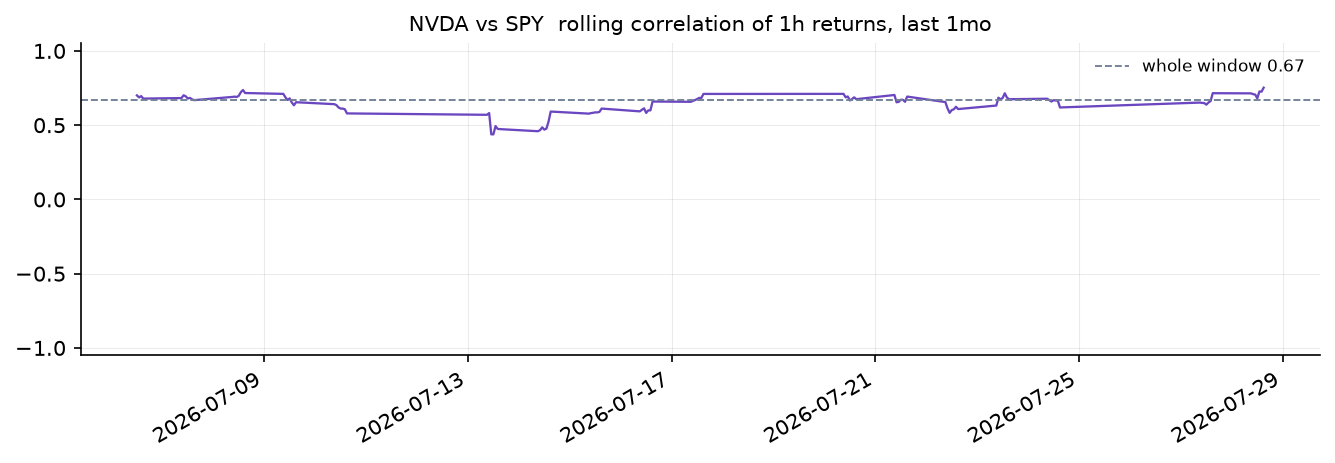

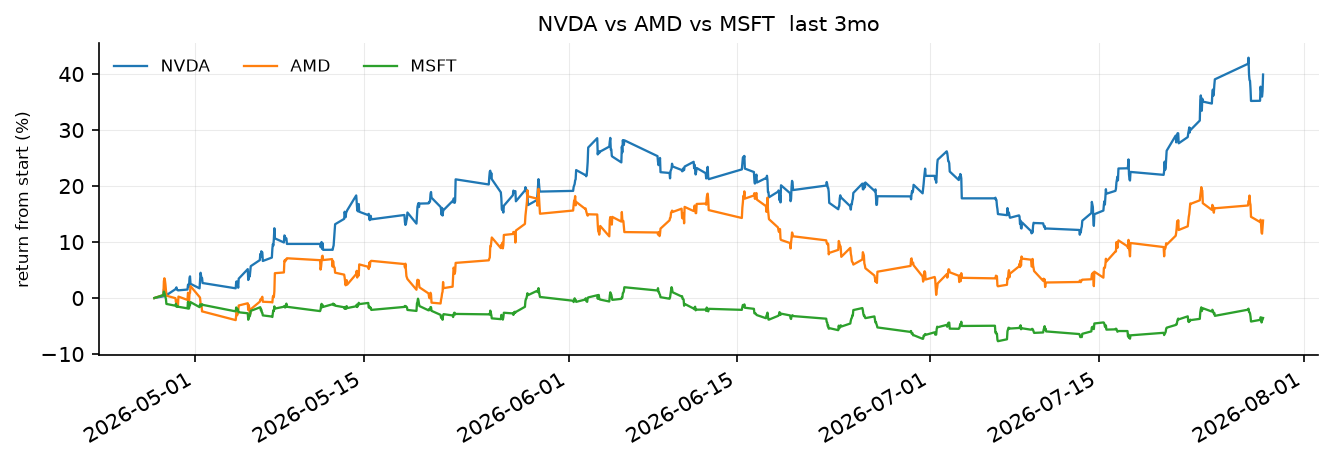

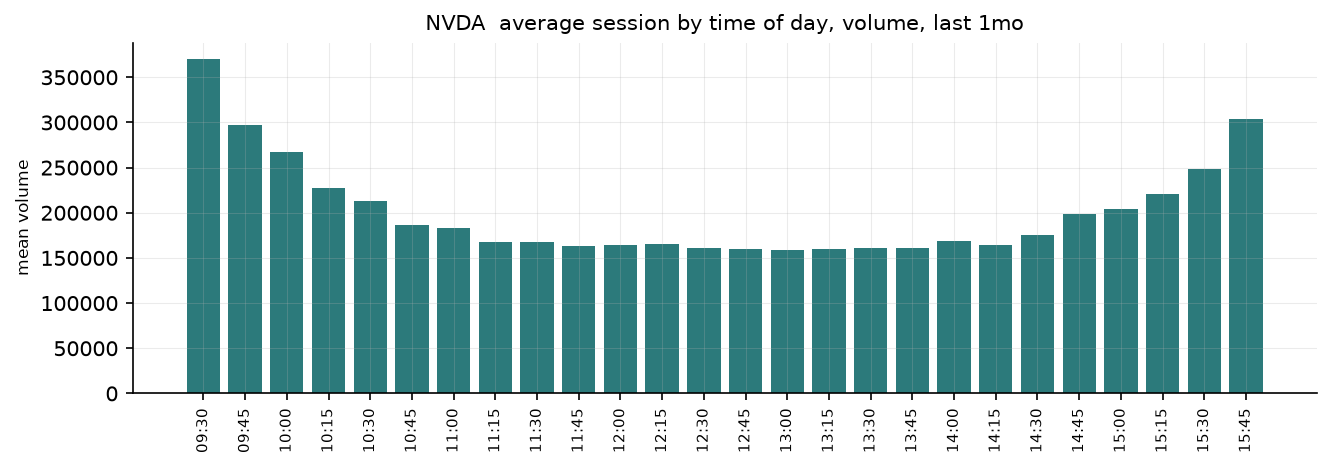

In [ ]:
for command in (
    "plot rolling correlation between nvda and spy for the past month",
    "compare nvda amd and msft over the past three months",
    "when during the day does nvda trade the most",
):
    print(f'"{command}"  ->  {CALLS[command]}')
    show(CALLS[command].run)

And the ones that answer in text:

In [ ]:
for command in ("how did the market do this week", "biggest losers today"):
    print(f'"{command}"  ->  {CALLS[command]}')
    print(CALLS[command].run(), "\n")

"how did the market do this week"  ->  market_summary(window='1w')
the board over 1w
  NVDA     254.12    9.62%    389,465,563
  AMD      184.20    1.51%    182,740,497
  AAPL     258.71    0.97%    223,818,998
  SPY      664.86    0.40%    138,617,365
  MSFT     451.35    0.26%    113,427,173
  TSLA     320.22   -0.97%    266,317,023 

"biggest losers today"  ->  top_movers(window='1d', direction='losers')
top 3 losers over 1d
  AMD      -0.57%  ->  184.20
  MSFT      0.67%  ->  451.35
  AAPL      1.40%  ->  258.71 


## Read the confidence

`confidence` reports the least certain judgement in the call, rather than the product of
all of them, since one wrong argument is enough to spoil the result. A product answers a
different question ("is every part right"), and it falls as a function takes more
arguments, whether or not any one judgement is shaky.

Where that number came from, argument by argument:

In [ ]:
call = CALLS["is amd tracking nvidia lately"]
print(f'"is amd tracking nvidia lately"  ->  {call}   confidence {call.confidence:.2f}')
for name, argument in call.arguments.items():
    top = sorted(argument.distribution.items(), key=lambda kv: -kv[1])[:3]
    shown = "omitted, default stands" if argument.omitted else repr(argument.value)
    print(
        f"  {name:<12}{shown:<26}p {argument.probability:.2f}   "
        + "  ".join(f"{k} {v:.2f}" for k, v in top)
    )
print(f"  weakest argument: {call.weakest().name}")

"is amd tracking nvidia lately"  ->  rolling_correlation(symbol='AMD', benchmark='NVDA')   confidence 0.69
  symbol      'AMD'                     p 0.93   AMD 0.93  NVDA 0.07  AAPL 0.00
  benchmark   'NVDA'                    p 0.69   NVDA 1.00  AAPL 0.00  AMD 0.00
  window      omitted, default stands   p 0.88   
  resolution  omitted, default stands   p 0.95   
  weakest argument: benchmark


`window` and `resolution` are both omitted here, because "lately" does not say how far back
or on what bars, so `rolling_correlation` runs on its own defaults of one month and hourly
bars. That is what the `stated` question is for. Without it, the choice would have to name
some window even though the command names none.

## Open it in the playground

The link below holds one command and the questions for the function it picked: the choice
over the ten function descriptions, and `rolling_correlation`'s four arguments. Edit the
command there and the arguments change with it.

In [ ]:
COMMAND = "plot rolling correlation between nvda and spy for the past month"
picked = CALLS[COMMAND]
playground_link = make_playground_link(
    COMMAND,
    {ROUTE: assistant.questions[ROUTE]}
    | {q: v for q, v in assistant.questions.items() if q.startswith(f"{picked.name}.")},
)
display(
    Markdown(
        f"🔗 [Open the command and its questions in the TypeSafe playground]({playground_link})"
    )
)

🔗 [Open the command and its questions in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIADgDYQr4BOEJJAlkgOb5QSWUIkCGKdES+AEYIUAdwTJ8SAG5gu+LkjD4AzkQCe+AGZt8KABYJ8RLiopx+BkABpCRanCIoVGbHkLAAOiAD6PlBA0ft4EXiAo6kQIIfjeUPoQdFDRNrEgDGaUMFC8-Cox3gDq+jz4dCp6hvgwKgiUCioA1gzMBkYolFxgLQ0q5SiKFAH4kAD83rZxlHQodXRcMWH0Zj4q6nCCNPnu3mhVNXX4ooMVw41IEKJH+kn6quubJBW6CVdw2Xc3Zmya5fhkXQQYFsFyGEFUEgUSE0JkovFg3Hq8S4cPwuiQ8GElAmaTgKMaIlW8DxlHUBRAeyMB3qx1QzyQRnoDOMhzWGxoqlePVelSMogSJCMmxRygs0iBtlEMzuF1ULUF93ZJDlTEFyggMBQOO8pHIPnsSRSBF2+1qNJOenBZAgjQUFH4RjZjwA5BUDck0eL6rxEA0FCwSnDtelUJ05Op9TxZpQkOTKdUzQ1GhUefIIkQklxlR0uj1w-hGBAEBUdPUHYrHvgALTXUolIhRJAVUptNGN2ylOB0MDh2wMYatqBkWrB1iOFEIHwcFAwGPbY0U02HWnOPSicG6CwcCtbNECVsqLi+5Go4a1Pk3eIjbtCETR4PUWgtHysdicHh8WM7RdUxMr07gue+A8kOEC1CQmhiIBDy7iU4q3pIYo9AEjAiIYlAdkowGXJUdamAGiioWAwYqMSKIRmYPDzmk8bUkcFpplwggKhAWhSJidQlro5ZOhyNY3Iw+gqLYZCiMJChelwqH4GKCC2AEAzKtOs5fpMIDSDQH70BEcZLvUpjJthVwadwvCCrY8QQA26i2Lo0xNJoPEwcqJQVMIyDBgERA+LJlDUSav7LgxVCKASyjLPabH8rcO5PFQYFGLoWicNmVQWGYwZgJ0oiQKIX4LrRiYGSmOFaCie6Os52gpdoDj+lEXCNH2q7rn5FBgAgQ4MCkAC+PVqY+TKMC+bAcKZn4AHS8SQizeOmRppJZhrBhkHTZLkTbksUMXfFAtp-K2dEGT0TEahQNatuWwg9IgpizhKUhHkC2h0G14ypFMMxzAs7hhAAygACgAmuSgNA-JVR-QAZAD+AAKwAAwI2UShYPgACiaAAGIQ0YJIEhQ+HyPyNApGpAByABqAAiACC5Lk9I3bzLZWizAIojTCg7P4FTdPBrTACy1PkkL1O2LTYDSIoyTKILSTUPg1MIEzyTbGptO0wDAAyosNuZaJs5InMzDzms68Ggt-VjaDkvLUDUCorEoKzPMm9zkhWzbwZoH92v09+GAqNwrvG1zPO+-73h9QNNBDSNb7jfwE3CEg8T47N4SRAtcQJMtH0hpk62fv5IDbVeu37RUMy3j0Y6ws9UlcKt1a8hCrBYeWSBPcCbfqCKZhJI071qQ7X3TD9oTeGDoPA7j+DQ7DiPIwwHWYBj2Pz-jIh+sTApk2kfMBwujPM1wocc+HkhHwLwui8LEtSzLz324ryuq8WAta7r360-rcmGzdlfAQ5sf5qS9rbb8r8wLOwvkcYB+AIE+z9sfGixYQ6ALDqbSQkcA4xzSINZ8r4xofmTqndO+J3pTyzlEckFwYAzQLqtLIOQS7kmpkWU4elHq+nkLUDuyhpqWhYBAcc24m6rXev1AhcciGjXfBtCaUolCXEzvNckS1kgrSbGtVheRyQAAlSrlUEFwPaZQuGBX0k0E6mxNStwCL2NuJgzBHAkE1ZxphzCWH0LZb0VQXFDH0BwPGPiVAj0Wlzb6mcACMxFvyOK4DZNuplixDDDD0WoKg+j8D3BBYMMTRDklbIEtxCBGgFIsMUgJXiZI+ODAAZiqQkmpriDAhLqagISHZ8AAEcYAonvCAfB3hCFMATiQxRyjcpUPwGEdR356GMLUsw4u+jvwcOLG3Oih5NA8jKvUUx5jhjWg8aRK8+FEnJIMH8cQ5SIZ-AsF0vxlQ-j9MGXUKRscnzjOIQoyaHAnYkE1J+NR2cNF5y0UwnRLCNql2KKUUx9Q+gAC9HQJAYcoVsyk5y3hkggO6HB1QCBrOWLsGJZi2C0HQeC5LNTFipXQI2iEGD0vEuWDFGE0RlmZOGCJn1ozzFiXAckDoqx0tmFQEQKl1ZpDhiK781LxTitZZKnFm0C4xPleSalzKkAqopUYdVsrvAxP0OSTlEEpUzjnAU+JC45B0Ctca6O0jRmyN+fIpOSAJqApoCC-gsz5ngsWRqZZaRVl6I1QuTZliEysiSbWCgSK5Rou5SjaM0tszgluqRbcxq9xSJ6qkEAXAMyU04p+dw6kYnDKAA)